In [2]:
# !pip install scikit-learn pandas numpy matplotlib seaborn wordcloud

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from scipy.sparse import vstack

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [3]:
import os

OUTPUT_DIR = 'outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("[INFO] Environment setup completed. Output directory created.")

[INFO] Environment setup completed. Output directory created.


In [ ]:
import os
import pandas as pd

BASE_DIR = 'IR'

# Load TSV files (without headers)
print("[INFO] Loading train.tsv and dev.tsv...")
train_df = pd.read_csv(os.path.join(BASE_DIR, 'train.tsv'), sep='\t', header=None, names=['Fileindex', 'Category'])
dev_df = pd.read_csv(os.path.join(BASE_DIR, 'dev.tsv'), sep='\t', header=None, names=['Fileindex', 'Category'])

id_col = 'Fileindex'
label_col = 'Category'

print(f"[INFO] Train shape: {train_df.shape}, Dev shape: {dev_df.shape}")
print(f"[INFO] Sample Fileindex from train TSV: '{train_df[id_col].iloc[0]}'")

# 1. Scan the entire BASE_DIR to find all .txt files and map them intelligently
print("\n[INFO] Scanning all .txt files in the dataset directory...")
all_txt_files_map = {}
basename_map = {}

for root, dirs, files in os.walk(BASE_DIR):
    for file in files:
        if file.endswith('.txt'):
            file_path = os.path.join(root, file)
            rel_path = os.path.relpath(file_path, BASE_DIR)
            
            # Map exact relative path and filename
            all_txt_files_map[file] = file_path
            all_txt_files_map[rel_path] = file_path
            
            # Map without 'speech/' prefix (fixes the missing 'speech/' issue in TSV)
            if rel_path.startswith('speech/'):
                all_txt_files_map[rel_path[len('speech/'):]] = file_path
                
            # Map basename
            if file not in basename_map:
                basename_map[file] = file_path

print(f"[INFO] Found {len(set(all_txt_files_map.values()))} unique .txt files in the directory.")

# 2. Function to load texts using the smart map
def load_texts_using_map(df, id_column):
    texts = []
    valid_indices = []
    missing_count = 0
    
    for idx, file_id in enumerate(df[id_column]):
        file_id_str = str(file_id).strip()
        file_path = None
        
        # Try exact matches first (with and without .txt, with and without speech/)
        for candidate in [file_id_str, file_id_str + '.txt', 
                    'speech/' + file_id_str, 'speech/' + file_id_str + '.txt']:
            if candidate in all_txt_files_map:
                file_path = all_txt_files_map[candidate]
                break
                
        # Fallback to basename (just the file name like 00013.txt)
        if not file_path:
            basename = os.path.basename(file_id_str)
            if not basename.endswith('.txt'):
                basename += '.txt'
            file_path = basename_map.get(basename)
            
        if file_path and os.path.exists(file_path):
            with open(file_path, 'r', encoding='utf-8') as f:
                texts.append(f.read().strip())
            valid_indices.append(idx)
        else:
            texts.append("")
            missing_count += 1
            if missing_count <= 3:
                print(f"[WARNING] File not found for ID: '{file_id_str}'")
                
    if missing_count > 3:
        print(f"[WARNING] ... and {missing_count - 3} more files not found.")
    elif missing_count == 0:
        print(f"[INFO] Successfully found all {len(df)} files!")
        
    return texts, valid_indices

print("\n[INFO] Loading labeled texts for Train set...")
train_texts, train_valid_idx = load_texts_using_map(train_df, id_col)
train_df = train_df.iloc[train_valid_idx].reset_index(drop=True)
train_texts = [train_texts[i] for i in train_valid_idx]

print("\n[INFO] Loading labeled texts for Dev set...")
dev_texts, dev_valid_idx = load_texts_using_map(dev_df, id_col)
dev_df = dev_df.iloc[dev_valid_idx].reset_index(drop=True)
dev_texts = [dev_texts[i] for i in dev_valid_idx]

# 3. Load unlabeled texts
print("\n[INFO] Loading unlabeled texts...")
unlabeled_texts = []
unlabeled_ids = []

# Find the unlabeled directory dynamically
unlabeled_dir = None
for root, dirs, files in os.walk(BASE_DIR):
    if 'unlabeled' in root:
        if any(f.endswith('.txt') for f in files):
            unlabeled_dir = root
            break

if unlabeled_dir:
    print(f"[INFO] Found unlabeled directory: {unlabeled_dir}")
    for file in sorted(os.listdir(unlabeled_dir)):
        if file.endswith('.txt'):
            file_path = os.path.join(unlabeled_dir, file)
            with open(file_path, 'r', encoding='utf-8') as f:
                unlabeled_texts.append(f.read().strip())
            unlabeled_ids.append(file.replace('.txt', ''))
else:
    print("[WARNING] 'unlabeled' directory not found. Checking for other .txt files...")
    labeled_ids_set = set(train_df[id_col].astype(str)) | set(dev_df[id_col].astype(str))
    for root, dirs, files in os.walk(BASE_DIR):
        for file in files:
            if file.endswith('.txt'):
                file_id = file.replace('.txt', '')
                if file_id not in labeled_ids_set and file not in labeled_ids_set:
                    file_path = os.path.join(root, file)
                    with open(file_path, 'r', encoding='utf-8') as f:
                        unlabeled_texts.append(f.read().strip())
                    unlabeled_ids.append(file_id)

print(f"\n[INFO] Data loading complete.")
print(f"[INFO] Train samples loaded: {len(train_texts)}")
print(f"[INFO] Dev samples loaded: {len(dev_texts)}")
print(f"[INFO] Unlabeled samples loaded: {len(unlabeled_texts)}")

[INFO] Loading train.tsv and dev.tsv...
[INFO] Train shape: (4370, 2), Dev shape: (414, 2)
[INFO] Sample Fileindex from train TSV: 'labeled/00013.txt'

[INFO] Scanning all .txt files in the dataset directory...
[INFO] Found 6361 unique .txt files in the directory.

[INFO] Loading labeled texts for Train set...
[WARNING] File not found for ID: 'labeled/00013.txt'
[WARNING] File not found for ID: 'labeled/32688.txt'
[WARNING] File not found for ID: 'labeled/32692.txt'
[WARNING] ... and 2514 more files not found.

[INFO] Loading labeled texts for Dev set...
[WARNING] File not found for ID: 'labeled/33097.txt'
[WARNING] File not found for ID: 'labeled/33199.txt'
[WARNING] File not found for ID: 'labeled/33399.txt'
[WARNING] ... and 253 more files not found.

[INFO] Loading unlabeled texts...
[WARNING] 'unlabeled' directory not found. Checking for other .txt files...

[INFO] Data loading complete.
[INFO] Train samples loaded: 1853
[INFO] Dev samples loaded: 158
[INFO] Unlabeled samples load

In [5]:
import re

def preprocess_text(text):
    if not text or not text.strip():
        return ""
    text = text.lower()
    # Keep letters, numbers, and spaces. Remove punctuation.
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print("[INFO] Preprocessing text data...")
X_train = [preprocess_text(t) for t in train_texts]
X_dev = [preprocess_text(t) for t in dev_texts]
X_unlabeled = [preprocess_text(t) for t in unlabeled_texts]

y_train = train_df[label_col].values
y_dev = dev_df[label_col].values

# --- Diagnostic Checks ---
non_empty_train = [t for t in X_train if t]
print(f"[INFO] Total X_train samples: {len(X_train)}")
print(f"[INFO] Non-empty X_train samples after preprocessing: {len(non_empty_train)}")

if len(non_empty_train) == 0:
    print("[ERROR] All texts are empty! The files were not read correctly.")
    print("[DEBUG] Sample raw train_texts[0]:", repr(train_texts[0][:100]) if train_texts else "EMPTY LIST")
else:
    print(f"[INFO] Sample preprocessed text: '{non_empty_train[0][:100]}...'")

print("[INFO] Text preprocessing completed.")

[INFO] Preprocessing text data...
[INFO] Total X_train samples: 1853
[INFO] Non-empty X_train samples after preprocessing: 1853
[INFO] Sample preprocessed text: 'constitution then there would be then you would have the full understanding how you would have a pea...'
[INFO] Text preprocessing completed.


In [6]:
print("[INFO] Extracting TF-IDF features...")

# Fit vectorizer on both train and unlabeled data to capture the full vocabulary
all_texts_for_vocab = X_train + X_unlabeled

vectorizer = TfidfVectorizer(
    max_features=15000,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

vectorizer.fit(all_texts_for_vocab)

X_train_tfidf = vectorizer.transform(X_train)
X_dev_tfidf = vectorizer.transform(X_dev)
X_unlabeled_tfidf = vectorizer.transform(X_unlabeled)

print(f"[INFO] TF-IDF extraction completed. Feature dimension: {X_train_tfidf.shape[1]}")

[INFO] Extracting TF-IDF features...
[INFO] TF-IDF extraction completed. Feature dimension: 15000


In [7]:
print("[INFO] Training supervised baseline model with hyperparameter tuning...")

param_grid = {
    'C': [0.1, 1.0, 10.0],
    'class_weight': ['balanced', None]
}

base_lr = LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')

grid_search = GridSearchCV(
    base_lr, 
    param_grid, 
    cv=3, 
    scoring='accuracy', 
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train_tfidf, y_train)

supervised_model = grid_search.best_estimator_
y_pred_supervised = supervised_model.predict(X_dev_tfidf)
acc_supervised = accuracy_score(y_dev, y_pred_supervised)

print(f"[INFO] Best hyperparameters: {grid_search.best_params_}")
print(f"[INFO] Supervised Model Accuracy on Dev Set: {acc_supervised:.4f}")

[INFO] Training supervised baseline model with hyperparameter tuning...
[INFO] Best hyperparameters: {'C': 10.0, 'class_weight': 'balanced'}
[INFO] Supervised Model Accuracy on Dev Set: 0.3291


In [8]:
print("[INFO] Training semi-supervised model using Self-Training...")

X_combined = vstack([X_train_tfidf, X_unlabeled_tfidf])
y_combined = np.concatenate([y_train, [-1] * len(X_unlabeled)])

base_estimator = LogisticRegression(
    max_iter=1000, 
    C=grid_search.best_params_['C'], 
    class_weight=grid_search.best_params_.get('class_weight', 'balanced'), 
    random_state=42,
    solver='liblinear'
)

semi_supervised_model = SelfTrainingClassifier(
    base_estimator=base_estimator,
    threshold=0.85,
    criterion='threshold',
    max_iter=10,
    verbose=False
)

semi_supervised_model.fit(X_combined, y_combined)

y_pred_semi = semi_supervised_model.predict(X_dev_tfidf)
acc_semi = accuracy_score(y_dev, y_pred_semi)

print(f"[INFO] Semi-Supervised Model Accuracy on Dev Set: {acc_semi:.4f}")
print(f"[INFO] Accuracy Improvement: {acc_semi - acc_supervised:+.4f}")
print(f"[INFO] Self-Training Iterations: {semi_supervised_model.n_iter_}")

[INFO] Training semi-supervised model using Self-Training...
[INFO] Semi-Supervised Model Accuracy on Dev Set: 0.3291
[INFO] Accuracy Improvement: +0.0000
[INFO] Self-Training Iterations: 1


[INFO] Generating Confusion Matrices...


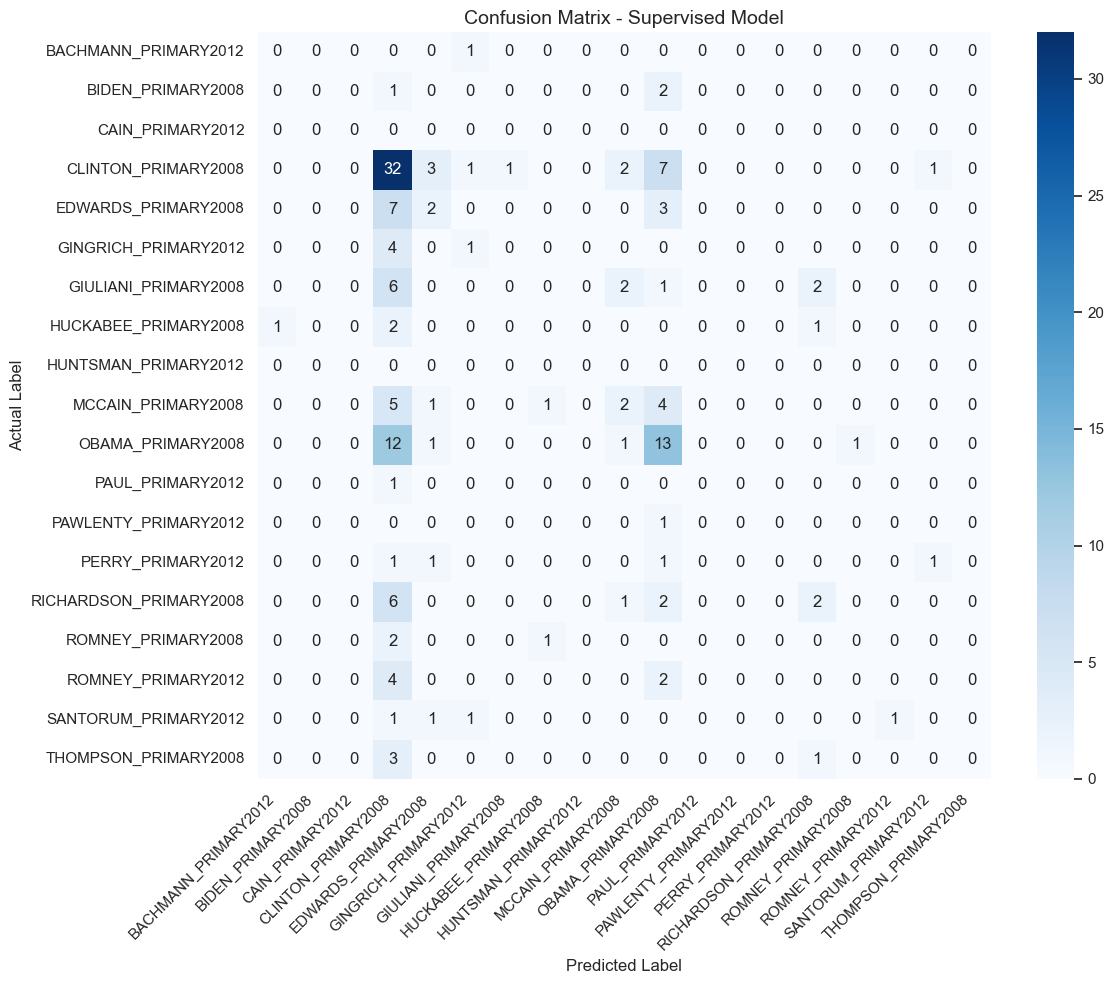

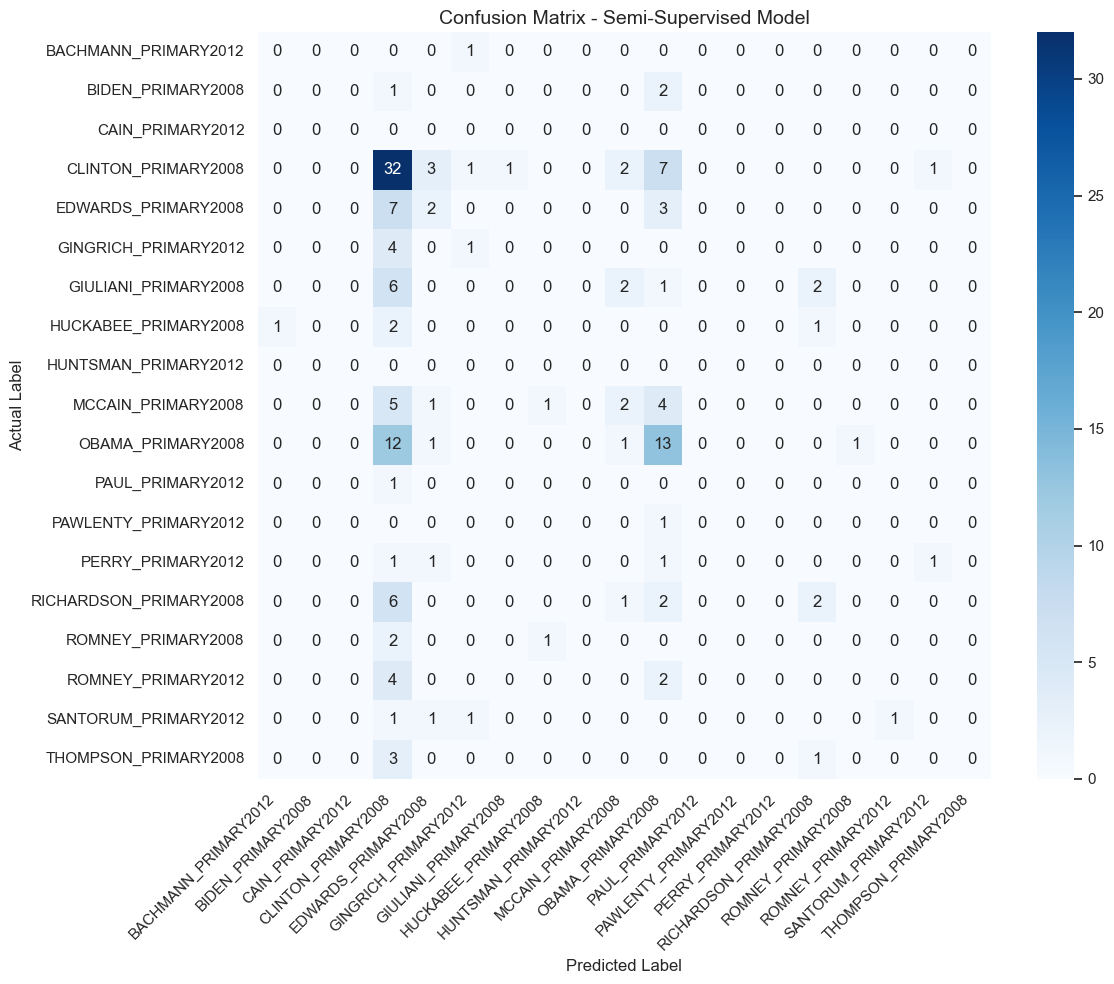

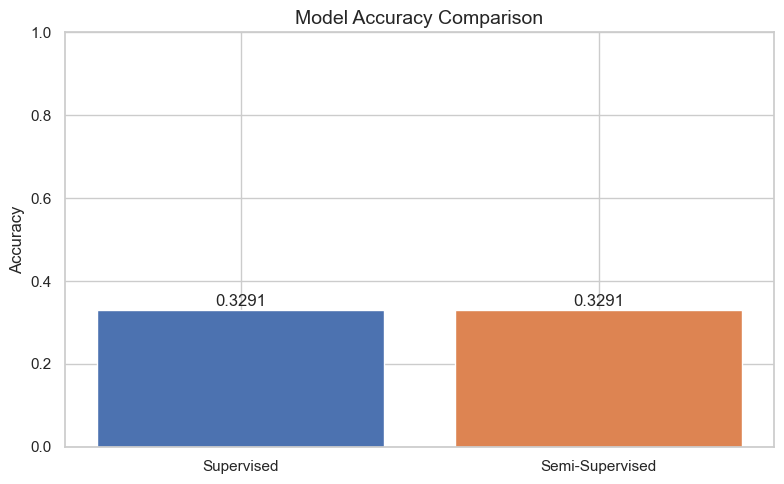

In [9]:
def plot_and_save_confusion_matrix(y_true, y_pred, model_classes, title, filename):
    cm = confusion_matrix(y_true, y_pred, labels=model_classes)
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', 
        xticklabels=model_classes, yticklabels=model_classes
    )
    plt.title(title, fontsize=14)
    plt.ylabel('Actual Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=150)
    plt.show()

print("[INFO] Generating Confusion Matrices...")
plot_and_save_confusion_matrix(
    y_dev, y_pred_supervised, supervised_model.classes_, 
    'Confusion Matrix - Supervised Model', 'cm_supervised.png'
)

plot_and_save_confusion_matrix(
    y_dev, y_pred_semi, semi_supervised_model.classes_, 
    'Confusion Matrix - Semi-Supervised Model', 'cm_semi_supervised.png'
)

# Model Comparison Bar Chart
plt.figure(figsize=(8, 5))
models = ['Supervised', 'Semi-Supervised']
accuracies = [acc_supervised, acc_semi]
bars = plt.bar(models, accuracies, color=['#4C72B0', '#DD8452'])
plt.ylim(0, 1)
plt.title('Model Accuracy Comparison', fontsize=14)
plt.ylabel('Accuracy', fontsize=12)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.4f}', ha='center', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'model_comparison.png'), dpi=150)
plt.show()

In [10]:
def analyze_top_features(model, vectorizer, class_name, n=10):
    if class_name not in model.classes_:
        return None, None
    
    class_idx = np.where(model.classes_ == class_name)[0][0]
    weights = model.coef_[class_idx]
    feature_names = np.array(vectorizer.get_feature_names_out())
    
    sorted_indices = np.argsort(weights)
    top_positive = feature_names[sorted_indices[-n:]][::-1]
    top_negative = feature_names[sorted_indices[:n]]
    
    return top_positive, top_negative

print("[INFO] Analyzing top features for selected candidates...")
target_classes = list(supervised_model.classes_)[:3]

for candidate in target_classes:
    top_pos, top_neg = analyze_top_features(supervised_model, vectorizer, candidate)
    print(f"\n[Candidate: {candidate}]")
    print(f"  Top Positive Features: {', '.join(top_pos)}")
    print(f"  Top Negative Features: {', '.join(top_neg)}")

[INFO] Analyzing top features for selected candidates...

[Candidate: BACHMANN_PRIMARY2012]
  Top Positive Features: team, israel, millions jews, stop, jews, iowa, speaks, constitution stop, wanted, entire campaign
  Top Negative Features: know, new, need, just, time, work, want, going, ve, care

[Candidate: BIDEN_PRIMARY2008]
  Top Positive Features: plan, sectarian, leave, troops, maybe lift, send, democratic reform, secret prisons, happens, defined permissible
  Top Negative Features: people, america, new, know, country, time, think, government, work, ve

[Candidate: CAIN_PRIMARY2012]
  Top Positive Features: new vision, god journey, god, vision, decision run, frustration decision, frustrated frustration, frustration, distractions false, false accusations
  Top Negative Features: president, know, need, going, just, time, think, work, country, make


[INFO] Analyzing the impact of unlabeled data percentage...
[INFO] Unlabeled Data: 0% -> Accuracy: 0.3291
[INFO] Unlabeled Data: 25% -> Accuracy: 0.3038
[INFO] Unlabeled Data: 50% -> Accuracy: 0.3038
[INFO] Unlabeled Data: 75% -> Accuracy: 0.3038
[INFO] Unlabeled Data: 100% -> Accuracy: 0.3038


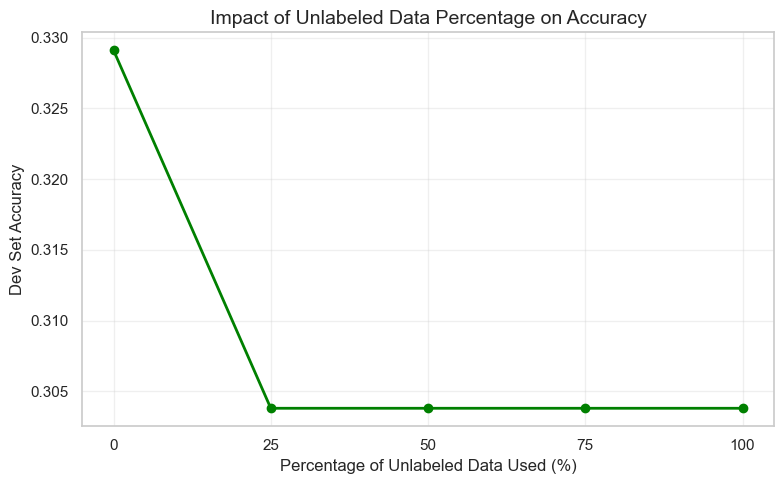

In [11]:
print("[INFO] Analyzing the impact of unlabeled data percentage...")

percentages = [0, 25, 50, 75, 100]
accuracies_unlabeled = []

for p in percentages:
    if p == 0:
        acc = acc_supervised
    else:
        n_unlabeled = int(len(X_unlabeled) * (p / 100.0))
        np.random.seed(42)
        selected_idx = np.random.choice(len(X_unlabeled), n_unlabeled, replace=False)
        
        X_subset = vstack([X_train_tfidf, X_unlabeled_tfidf[selected_idx]])
        y_subset = np.concatenate([y_train, [-1] * n_unlabeled])
        
        temp_base = LogisticRegression(max_iter=1000, C=1.0, class_weight='balanced', random_state=42, solver='liblinear')
        temp_model = SelfTrainingClassifier(temp_base, threshold=0.85, max_iter=10, verbose=False)
        temp_model.fit(X_subset, y_subset)
        
        acc = accuracy_score(y_dev, temp_model.predict(X_dev_tfidf))
    
    accuracies_unlabeled.append(acc)
    print(f"[INFO] Unlabeled Data: {p}% -> Accuracy: {acc:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(percentages, accuracies_unlabeled, marker='o', linewidth=2, color='green')
plt.title('Impact of Unlabeled Data Percentage on Accuracy', fontsize=14)
plt.xlabel('Percentage of Unlabeled Data Used (%)', fontsize=12)
plt.ylabel('Dev Set Accuracy', fontsize=12)
plt.xticks(percentages)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'unlabeled_data_impact.png'), dpi=150)
plt.show()

In [12]:
print("[INFO] Performing error analysis on the Dev set...")

errors_idx = np.where(y_dev != y_pred_semi)[0]
error_rate = len(errors_idx) / len(y_dev)

print(f"[INFO] Total Errors: {len(errors_idx)} out of {len(y_dev)} samples (Error Rate: {error_rate:.2%})")

if len(errors_idx) > 0:
    error_pairs = Counter(zip(y_dev[errors_idx], y_pred_semi[errors_idx]))
    print("\n[INFO] Top 5 Most Common Misclassifications (Actual -> Predicted):")
    for (actual, predicted), count in error_pairs.most_common(5):
        print(f"  {actual} -> {predicted}: {count} cases")

    print("\n[INFO] Sample Misclassified Texts:")
    for i in errors_idx[:3]:
        print(f"\n  - Actual: {y_dev[i]} | Predicted: {y_pred_semi[i]}")
        print(f"    Text Preview: {X_dev[i][:150]}...")

[INFO] Performing error analysis on the Dev set...
[INFO] Total Errors: 106 out of 158 samples (Error Rate: 67.09%)

[INFO] Top 5 Most Common Misclassifications (Actual -> Predicted):
  OBAMA_PRIMARY2008 -> CLINTON_PRIMARY2008: 12 cases
  CLINTON_PRIMARY2008 -> OBAMA_PRIMARY2008: 7 cases
  EDWARDS_PRIMARY2008 -> CLINTON_PRIMARY2008: 7 cases
  RICHARDSON_PRIMARY2008 -> CLINTON_PRIMARY2008: 6 cases
  GIULIANI_PRIMARY2008 -> CLINTON_PRIMARY2008: 6 cases

[INFO] Sample Misclassified Texts:

  - Actual: MCCAIN_PRIMARY2008 | Predicted: CLINTON_PRIMARY2008
    Text Preview: everywhere in the world because of them because i know that to be denied liberty is an offense to nature and nature s creator i will...

  - Actual: SANTORUM_PRIMARY2012 | Predicted: GINGRICH_PRIMARY2012
    Text Preview: companies can compete with anybody around the world the other thing that is key in making us competitive is energy energy is key to...

  - Actual: MCCAIN_PRIMARY2008 | Predicted: CLINTON_PRIMARY2008
    

In [13]:
print("[INFO] Generating submission file for Kaggle...")

y_unlabeled_pred = semi_supervised_model.predict(X_unlabeled_tfidf)

submission_df = pd.DataFrame({
    'Fileindex': range(len(unlabeled_ids)),
    'Category': y_unlabeled_pred
})

submission_path = os.path.join(OUTPUT_DIR, 'submission.csv')
submission_df.to_csv(submission_path, index=False)

print(f"[INFO] Submission file saved successfully at: {submission_path}")
print(f"[INFO] Total predictions generated: {len(submission_df)}")

# Display prediction distribution
pred_distribution = submission_df['Category'].value_counts()
print("\n[INFO] Prediction Distribution Across Candidates:")
print(pred_distribution.to_string())

[INFO] Generating submission file for Kaggle...
[INFO] Submission file saved successfully at: outputs\submission.csv
[INFO] Total predictions generated: 6361

[INFO] Prediction Distribution Across Candidates:
Category
CLINTON_PRIMARY2008       2951
OBAMA_PRIMARY2008         1367
MCCAIN_PRIMARY2008         422
EDWARDS_PRIMARY2008        337
RICHARDSON_PRIMARY2008     306
GIULIANI_PRIMARY2008       193
GINGRICH_PRIMARY2012       138
ROMNEY_PRIMARY2012         129
SANTORUM_PRIMARY2012       129
HUCKABEE_PRIMARY2008        98
THOMPSON_PRIMARY2008        92
PAUL_PRIMARY2012            44
ROMNEY_PRIMARY2008          41
PERRY_PRIMARY2012           28
BACHMANN_PRIMARY2012        24
BIDEN_PRIMARY2008           22
PAWLENTY_PRIMARY2012        21
HUNTSMAN_PRIMARY2012        12
CAIN_PRIMARY2012             7


In [14]:
import os
import shutil
import glob
from datetime import datetime

print("[INFO] Preparing final output package...")

# Create final output directory
FINAL_OUTPUT_DIR = 'final_project_outputs'
if os.path.exists(FINAL_OUTPUT_DIR):
    shutil.rmtree(FINAL_OUTPUT_DIR)
os.makedirs(FINAL_OUTPUT_DIR)

# 1. Collect all generated plots and files
print("[INFO] Collecting generated files...")

# Files to collect from outputs directory
output_files_patterns = [
    'outputs/*.png',
    'outputs/*.csv',
    'outputs/*.txt',
    '*.png',  # In case plots were saved in root
    '*.csv',
    '*.txt'
]

collected_files = []
for pattern in output_files_patterns:
    files = glob.glob(pattern)
    for file in files:
        if os.path.exists(file) and os.path.isfile(file):
            # Skip the notebook itself and temporary files
            if file.endswith('.ipynb') or file.endswith('.zip'):
                continue
            dest_path = os.path.join(FINAL_OUTPUT_DIR, os.path.basename(file))
            shutil.copy2(file, dest_path)
            collected_files.append(os.path.basename(file))
            print(f"  - Copied: {os.path.basename(file)}")

# 2. Create a comprehensive results summary file
print("\n[INFO] Creating results summary file...")

summary_path = os.path.join(FINAL_OUTPUT_DIR, 'RESULTS_SUMMARY.txt')
with open(summary_path, 'w', encoding='utf-8') as f:
    f.write("=" * 70 + "\n")
    f.write("PRESIDENTIAL CANDIDATE CLASSIFICATION - PROJECT RESULTS\n")
    f.write("=" * 70 + "\n\n")
    
    f.write(f"Generated on: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n\n")
    
    f.write("-" * 70 + "\n")
    f.write("DATASET STATISTICS\n")
    f.write("-" * 70 + "\n")
    f.write(f"Train samples: {len(train_texts)}\n")
    f.write(f"Dev samples: {len(dev_texts)}\n")
    f.write(f"Unlabeled samples: {len(unlabeled_texts)}\n")
    f.write(f"Number of candidates: {train_df[label_col].nunique()}\n\n")
    
    f.write("-" * 70 + "\n")
    f.write("FEATURE EXTRACTION\n")
    f.write("-" * 70 + "\n")
    f.write(f"TF-IDF max features: {vectorizer.max_features}\n")
    f.write(f"N-gram range: {vectorizer.ngram_range}\n")
    f.write(f"Vocabulary size: {len(vectorizer.vocabulary_)}\n\n")
    
    f.write("-" * 70 + "\n")
    f.write("MODEL PERFORMANCE\n")
    f.write("-" * 70 + "\n")
    f.write(f"Supervised Model (Logistic Regression):\n")
    f.write(f"  - Best parameters: {grid_search.best_params_}\n")
    f.write(f"  - Dev accuracy: {acc_supervised:.4f}\n\n")
    
    f.write(f"Semi-Supervised Model (Self-Training):\n")
    f.write(f"  - Dev accuracy: {acc_semi:.4f}\n")
    f.write(f"  - Improvement: {acc_semi - acc_supervised:+.4f}\n")
    f.write(f"  - Self-training iterations: {semi_supervised_model.n_iter_}\n")
    f.write(f"  - Final labeled set size: {sum(semi_supervised_model.transduction_ != -1)}\n\n")
    
    f.write("-" * 70 + "\n")
    f.write("PREDICTION DISTRIBUTION\n")
    f.write("-" * 70 + "\n")
    pred_dist = pd.Series(y_unlabeled_pred).value_counts()
    for candidate, count in pred_dist.items():
        f.write(f"{candidate}: {count}\n")
    f.write(f"\nTotal predictions: {len(y_unlabeled_pred)}\n\n")
    
    f.write("-" * 70 + "\n")
    f.write("ERROR ANALYSIS\n")
    f.write("-" * 70 + "\n")
    errors_idx = np.where(y_dev != y_pred_semi)[0]
    error_rate = len(errors_idx) / len(y_dev)
    f.write(f"Total errors: {len(errors_idx)} out of {len(y_dev)} samples\n")
    f.write(f"Error rate: {error_rate:.2%}\n\n")
    
    if len(errors_idx) > 0:
        error_pairs = Counter(zip(y_dev[errors_idx], y_pred_semi[errors_idx]))
        f.write("Top 5 misclassifications:\n")
        for (actual, predicted), count in error_pairs.most_common(5):
            f.write(f"  {actual} -> {predicted}: {count} cases\n")
    
    f.write("\n" + "=" * 70 + "\n")
    f.write("END OF SUMMARY\n")
    f.write("=" * 70 + "\n")

print(f"  - Created: RESULTS_SUMMARY.txt")

# 3. Create a README file
readme_path = os.path.join(FINAL_OUTPUT_DIR, 'README.txt')
with open(readme_path, 'w', encoding='utf-8') as f:
    f.write("=" * 70 + "\n")
    f.write("PRESIDENTIAL CANDIDATE CLASSIFICATION PROJECT\n")
    f.write("=" * 70 + "\n\n")
    
    f.write("This package contains the outputs of the semi-supervised text\n")
    f.write("classification project for identifying US presidential candidates\n")
    f.write("from speech excerpts.\n\n")
    
    f.write("CONTENTS:\n")
    f.write("-" * 70 + "\n")
    f.write("1. RESULTS_SUMMARY.txt - Comprehensive summary of all results\n")
    f.write("2. submission.csv - Kaggle submission file with predictions\n")
    f.write("3. model_comparison.png - Bar chart comparing model accuracies\n")
    f.write("4. cm_supervised.png - Confusion matrix for supervised model\n")
    f.write("5. cm_semi_supervised.png - Confusion matrix for semi-supervised model\n")
    f.write("6. unlabeled_data_impact.png - Impact of unlabeled data percentage\n")
    f.write("7. README.txt - This file\n\n")
    
    f.write("METHODOLOGY:\n")
    f.write("-" * 70 + "\n")
    f.write("- Feature Extraction: TF-IDF with unigrams and bigrams\n")
    f.write("- Supervised Model: Logistic Regression with GridSearchCV\n")
    f.write("- Semi-Supervised Model: Self-Training Classifier\n")
    f.write("- Evaluation: Accuracy on dev set\n\n")
    
    f.write("For detailed analysis, please refer to the project report (Report.pdf).\n\n")
    
    f.write("=" * 70 + "\n")

print(f"  - Created: README.txt")

# 4. List all files in the final output directory
print(f"\n[INFO] Files in {FINAL_OUTPUT_DIR}/:")
for file in sorted(os.listdir(FINAL_OUTPUT_DIR)):
    file_path = os.path.join(FINAL_OUTPUT_DIR, file)
    size_kb = os.path.getsize(file_path) / 1024
    print(f"  - {file} ({size_kb:.1f} KB)")

# 5. Create ZIP archive
print(f"\n[INFO] Creating ZIP archive...")
zip_filename = 'project_outputs_final'
zip_path = shutil.make_archive(zip_filename, 'zip', FINAL_OUTPUT_DIR)
zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"[SUCCESS] ZIP archive created: {zip_path} ({zip_size_mb:.2f} MB)")

# 6. Create download link (for JupyterLab)
print("\n[INFO] Preparing download...")
print(f"[INFO] Your ZIP file is ready at: {os.path.abspath(zip_path)}")
print("[INFO] You can download it from the file browser on the left sidebar.")
print("[INFO] Or use the following code to trigger a download dialog:\n")

# For JupyterLab, display the file path
from IPython.display import FileLink, display
print("Click the link below to download:")
display(FileLink(zip_path + '.zip'))

print("\n" + "=" * 70)
print("PACKAGE PREPARATION COMPLETE!")
print("=" * 70)
print(f"Total files: {len(os.listdir(FINAL_OUTPUT_DIR))}")
print(f"ZIP file size: {zip_size_mb:.2f} MB")
print(f"Location: {os.path.abspath(zip_path)}")
print("=" * 70)

[INFO] Preparing final output package...
[INFO] Collecting generated files...
  - Copied: cm_semi_supervised.png
  - Copied: cm_supervised.png
  - Copied: model_comparison.png
  - Copied: unlabeled_data_impact.png
  - Copied: submission.csv
  - Copied: 1.png
  - Copied: c6f8c08a-a334-4e82-841f-648f2c0d46cc.png
  - Copied: download.png
  - Copied: عکس 2.png
  - Copied: عکس پرسنلی.png
  - Copied: speech-basic.csv
  - Copied: speech-pred.csv

[INFO] Creating results summary file...
  - Created: RESULTS_SUMMARY.txt
  - Created: README.txt

[INFO] Files in final_project_outputs/:
  - 1.png (641.5 KB)
  - README.txt (1.3 KB)
  - RESULTS_SUMMARY.txt (2.5 KB)
  - c6f8c08a-a334-4e82-841f-648f2c0d46cc.png (134.5 KB)
  - cm_semi_supervised.png (348.8 KB)
  - cm_supervised.png (348.0 KB)
  - download.png (457.7 KB)
  - model_comparison.png (33.4 KB)
  - speech-basic.csv (1005.0 KB)
  - speech-pred.csv (1075.6 KB)
  - submission.csv (158.5 KB)
  - unlabeled_data_impact.png (58.8 KB)
  - عکس 2.png (

C:\Users\Asus\project_outputs_final.zip.zip


PACKAGE PREPARATION COMPLETE!
Total files: 14
ZIP file size: 3.42 MB
Location: C:\Users\Asus\project_outputs_final.zip
